In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib import colors
from nilearn import plotting


In [2]:
condition_name = "pol"
degree_threshold = 5

notebook_dir = Path.cwd()
fc_path = notebook_dir / f"connectivity_threshold_pos_binary_{condition_name}.csv"
coord_path = notebook_dir / "xilin_268parc_labels.csv"

fc_mat = pd.read_csv(fc_path, header=None).values
coords_df = pd.read_csv(coord_path)
coords = coords_df[["MNI_X", "MNI_Y", "MNI_Z"]].values


In [3]:
node_degree = np.sum(fc_mat, axis=1)
keep_idx = np.where(node_degree > 0)[0]

if len(keep_idx) == 0:
    raise ValueError(f"No edges found in {fc_path.name}.")

fc_filtered = fc_mat[np.ix_(keep_idx, keep_idx)]
coords_filtered = coords[keep_idx]
node_degree_filtered = node_degree[keep_idx]
main_nodes = node_degree_filtered >= degree_threshold

node_colors = np.array([""] * len(node_degree_filtered), dtype=object)
node_colors[main_nodes] = "#FF2E63"

non_main_degrees = node_degree_filtered[~main_nodes]
if len(non_main_degrees) > 0:
    deg_min = np.min(non_main_degrees)
    deg_max = np.max(non_main_degrees)
    deg_scaled = (non_main_degrees - deg_min) / (deg_max - deg_min + 1e-8)
    cmap = colors.LinearSegmentedColormap.from_list("degree_cmap", ["#FFE0E8", "#FF2E63"])
    node_colors[~main_nodes] = [colors.to_hex(cmap(degree)) for degree in deg_scaled]

min_degree = np.min(node_degree_filtered)
degree_range = np.ptp(node_degree_filtered) + 1e-8
node_sizes = np.where(
    main_nodes,
    100 + 300 * (node_degree_filtered - min_degree) / degree_range,
    20 + 300 * (node_degree_filtered - min_degree) / degree_range,
)


<Figure size 700x350 with 0 Axes>

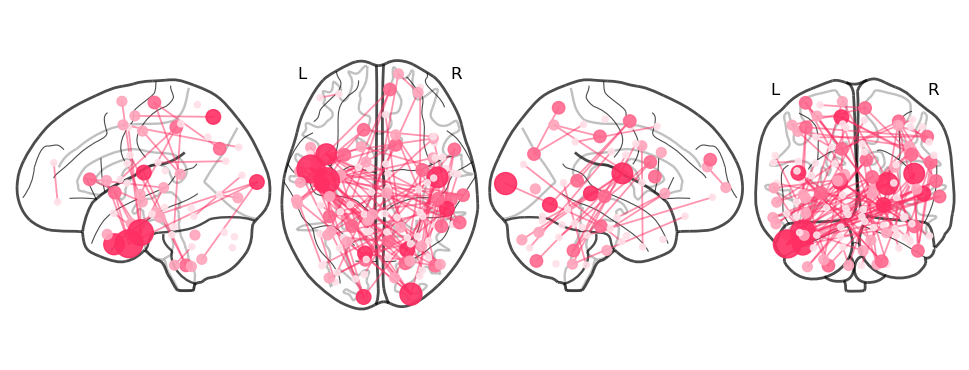

In [4]:
fig = plt.figure(figsize=(7, 3.5), facecolor="white")
display = plotting.plot_connectome(
    adjacency_matrix=fc_filtered,
    node_coords=coords_filtered,
    node_color=node_colors,
    node_size=node_sizes,
    display_mode="lzry",
    edge_kwargs={"linewidth": 1.3, "color": "#FF2E63", "alpha": 0.5},
    node_kwargs={"alpha": 0.9},
    colorbar=False,
    title="",
)
display.savefig(notebook_dir / f"connectome_pos_{condition_name}.png", dpi=300, bbox_inches="tight")


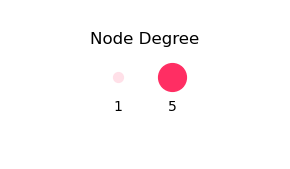

In [5]:
fig, ax = plt.subplots(figsize=(3, 1.8), facecolor="white")
ax.set_xlim(0, 3)
ax.set_ylim(0, 2)
ax.axis("off")

ax.text(1.5, 1.55, "Node Degree", fontsize=12, ha="center")
ax.scatter(1.2, 1.1, s=50, color="#FFE0E8", zorder=2)
ax.text(1.2, 0.65, "1", fontsize=10, ha="center")
ax.scatter(1.8, 1.1, s=400, color="#FF2E63", zorder=2)
ax.text(1.8, 0.65, str(degree_threshold), fontsize=10, ha="center")

plt.tight_layout()
plt.savefig(notebook_dir / "node_degree_legend_pos.png", dpi=300, bbox_inches="tight", transparent=True)
